In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style = "whitegrid")
np.random.seed(42)

In [11]:
study_hours=np.array([0.5,0.75,1,1.25,1.5,1.75,2,2.25,2.5,2.75,3,3.25,3.5,4,4.25,4.5,4.75,5,5.5])
pass_labels=np.array([0,0,0,0,0,0,1,0,0,1,0,1,0,1,1,1,1,1,1])

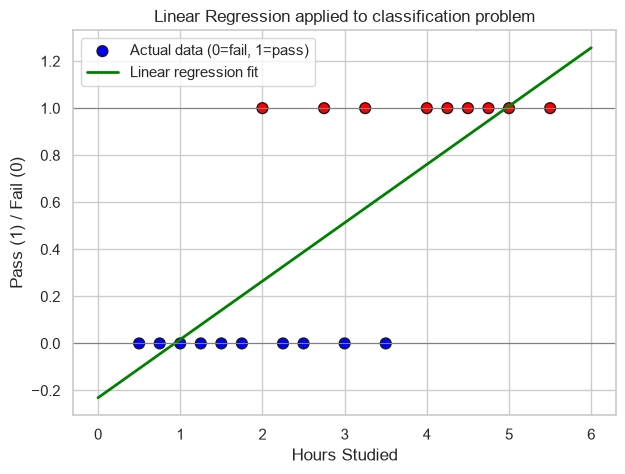

Prediction for 0 study hours: -0.23   (negative values are outside the valid probability range!)
Prediction for 6 study hours: 1.26   (values above 1 are outside the valid probability range!)


In [12]:
from sklearn.linear_model import LinearRegression

linear_fit=LinearRegression().fit(study_hours.reshape(-1,1),pass_labels)
hour_grid=np.linspace(0,6,100).reshape(-1,1)
linear_predictions=linear_fit.predict(hour_grid)

plt.figure(figsize=(7,5))
plt.scatter(study_hours,pass_labels,c=pass_labels,cmap='bwr',edgecolor='k',s=60,label='Actual data (0=fail, 1=pass)')
plt.plot(hour_grid,linear_predictions,color='green',linewidth=2,label='Linear regression fit')
plt.axhline(0,color='gray',linewidth=0.8)
plt.axhline(1,color='gray',linewidth=0.8)
plt.xlabel('Hours Studied')
plt.ylabel('Pass (1) / Fail (0)')
plt.title('Linear Regression applied to classification problem')
plt.legend()
plt.show()

print(f"Prediction for 0 study hours: {linear_fit.predict([[0]])[0]:.2f}   (negative values are outside the valid probability range!)")
print(f"Prediction for 6 study hours: {linear_fit.predict([[6]])[0]:.2f}   (values above 1 are outside the valid probability range!)")

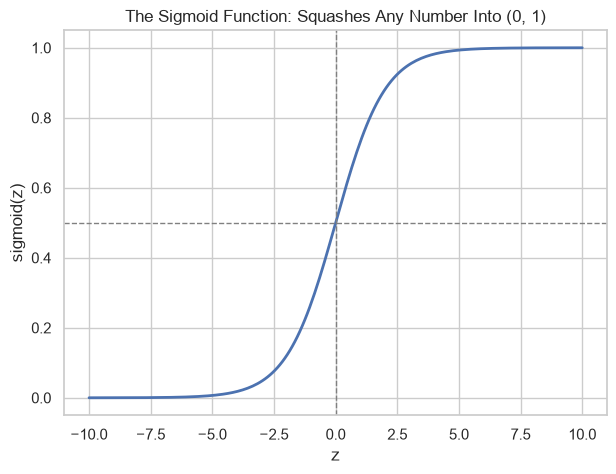

In [13]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 200)

plt.figure(figsize=(7,5))
plt.plot(z, sigmoid(z), linewidth=2)
plt.axhline(0.5, color='gray', linestyle='--', linewidth=1)
plt.axvline(0, color='gray', linestyle='--', linewidth=1)
plt.xlabel('z'); plt.ylabel('sigmoid(z)')
plt.title('The Sigmoid Function: Squashes Any Number Into (0, 1)')
plt.show()

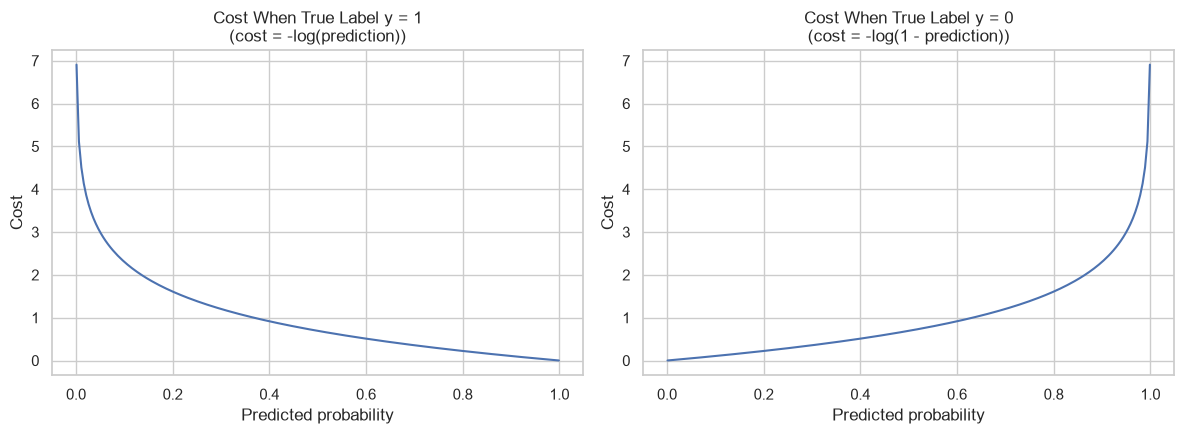

In [14]:
probability_grid = np.linspace(0.001, 0.999, 200)

plot_figure, plot_axes = plt.subplots(1, 2, figsize=(12,4.5))
plot_axes[0].plot(probability_grid, -np.log(probability_grid))
plot_axes[0].set_title('Cost When True Label y = 1\n(cost = -log(prediction))')
plot_axes[0].set_xlabel('Predicted probability'); plot_axes[0].set_ylabel('Cost')

plot_axes[1].plot(probability_grid, -np.log(1-probability_grid))
plot_axes[1].set_title('Cost When True Label y = 0\n(cost = -log(1 - prediction))')
plot_axes[1].set_xlabel('Predicted probability'); plot_axes[1].set_ylabel('Cost')

plt.tight_layout()
plt.show()


In [15]:
def logistic_gradient_descent(X, y, learning_rate=0.5, iterations=5000):
    m, n = X.shape
    features_with_bias = np.c_[np.ones((m, 1)), X]
    model_weights = np.zeros(n + 1)
    loss_history = []

    for _ in range(iterations):
        z = features_with_bias.dot(model_weights)
        estimated_probabilities = sigmoid(z)
        prediction_errors = estimated_probabilities - y
        weight_gradients = (1 / m) * features_with_bias.T.dot(prediction_errors)
        model_weights -= learning_rate * weight_gradients

        # Log Loss, with a tiny epsilon to avoid log(0)
        epsilon = 1e-10
        log_loss_value = -np.mean(y*np.log(estimated_probabilities+epsilon) + (1-y)*np.log(1-estimated_probabilities+epsilon))
        loss_history.append(log_loss_value)

    return model_weights, loss_history


In [19]:
model_weights, loss_history = logistic_gradient_descent(study_hours.reshape(-1,1), pass_labels, learning_rate=0.5, iterations=5000)
bias_weight, study_weight = model_weights
print(f"Manual gradient descent: intercept = {bias_weight:.4f}, coefficient = {study_weight:.4f}")

classification_cutoff = -bias_weight / study_weight
print(f"Classification boundary: {classification_cutoff:.2f} hours studied")


Manual gradient descent: intercept = -5.2186, coefficient = 1.7847
Classification boundary: 2.92 hours studied


In [20]:
from sklearn.linear_model import LogisticRegression

logistic_fit = LogisticRegression()
logistic_fit.fit(study_hours.reshape(-1,1), pass_labels)
print(f"Scikit-learn fit: intercept = {logistic_fit.intercept_[0]:.4f}, coefficient = {logistic_fit.coef_[0][0]:.4f}")


Scikit-learn fit: intercept = -3.7315, coefficient = 1.2643


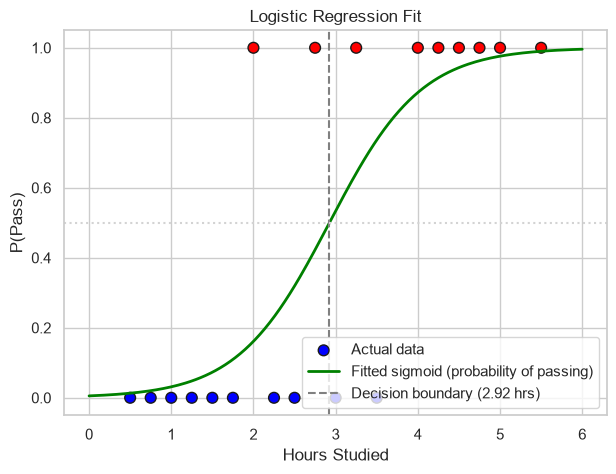

In [21]:
plt.figure(figsize=(7,5))
plt.scatter(study_hours, pass_labels, c=pass_labels, cmap='bwr', edgecolor='k', s=60, label='Actual data')
hour_grid = np.linspace(0, 6, 200)
plt.plot(hour_grid, sigmoid(bias_weight + study_weight*hour_grid), color='green', linewidth=2, label='Fitted sigmoid (probability of passing)')
plt.axvline(classification_cutoff, color='gray', linestyle='--', label=f'Decision boundary ({classification_cutoff:.2f} hrs)')
plt.axhline(0.5, color='lightgray', linestyle=':')
plt.xlabel('Hours Studied'); plt.ylabel('P(Pass)')
plt.title('Logistic Regression Fit')
plt.legend()
plt.show()


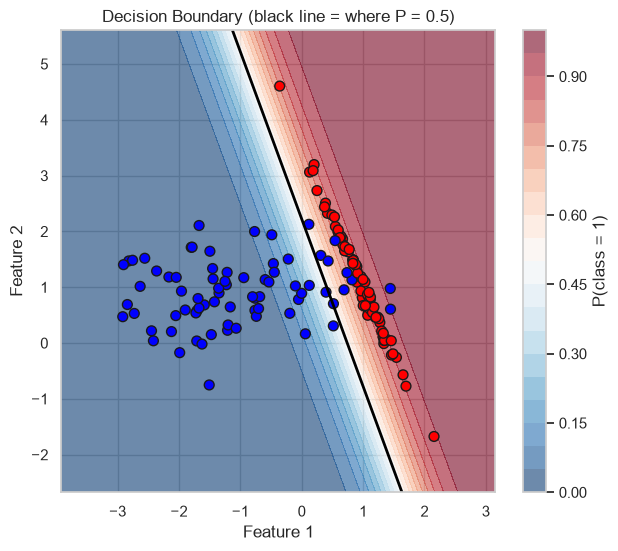

In [22]:
from sklearn.datasets import make_classification

binary_features, binary_labels = make_classification(n_samples=150, n_features=2, n_redundant=0, n_informative=2,
                              n_clusters_per_class=1, random_state=42)
boundary_model = LogisticRegression().fit(binary_features, binary_labels)

feature_x_grid, feature_y_grid = np.meshgrid(np.linspace(binary_features[:,0].min()-1, binary_features[:,0].max()+1, 200),
                      np.linspace(binary_features[:,1].min()-1, binary_features[:,1].max()+1, 200))
grid_predictions = boundary_model.predict_proba(np.c_[feature_x_grid.ravel(), feature_y_grid.ravel()])[:,1].reshape(feature_x_grid.shape)

plt.figure(figsize=(7,6))
plt.contourf(feature_x_grid, feature_y_grid, grid_predictions, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(label='P(class = 1)')
plt.contour(feature_x_grid, feature_y_grid, grid_predictions, levels=[0.5], colors='black', linewidths=2)   # the decision boundary itself
plt.scatter(binary_features[:,0], binary_features[:,1], c=binary_labels, cmap='bwr', edgecolor='k', s=50)
plt.title('Decision Boundary (black line = where P = 0.5)')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.show()


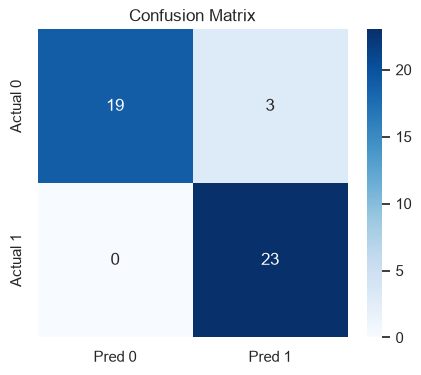

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

train_features, test_features, train_labels, test_labels = train_test_split(binary_features, binary_labels, test_size=0.3, random_state=42)
evaluation_model = LogisticRegression().fit(train_features, train_labels)
test_predictions = evaluation_model.predict(test_features)

binary_confusion = confusion_matrix(test_labels, test_predictions)
plt.figure(figsize=(5,4))
sns.heatmap(binary_confusion, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0','Pred 1'], yticklabels=['Actual 0','Actual 1'])
plt.title('Confusion Matrix')
plt.show()


In [24]:
print(classification_report(test_labels, test_predictions))


              precision    recall  f1-score   support

           0       1.00      0.86      0.93        22
           1       0.88      1.00      0.94        23

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



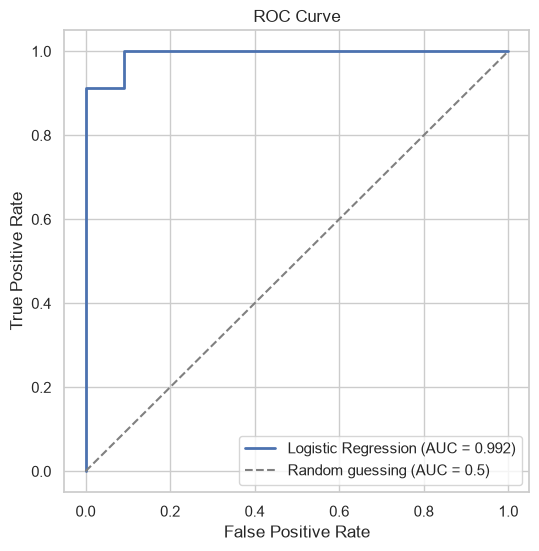

In [25]:
from sklearn.metrics import roc_curve, roc_auc_score

test_probabilities = evaluation_model.predict_proba(test_features)[:,1]
false_positive_rates, true_positive_rates, roc_thresholds = roc_curve(test_labels, test_probabilities)
auc_value = roc_auc_score(test_labels, test_probabilities)

plt.figure(figsize=(6,6))
plt.plot(false_positive_rates, true_positive_rates, linewidth=2, label=f'Logistic Regression (AUC = {auc_value:.3f})')
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


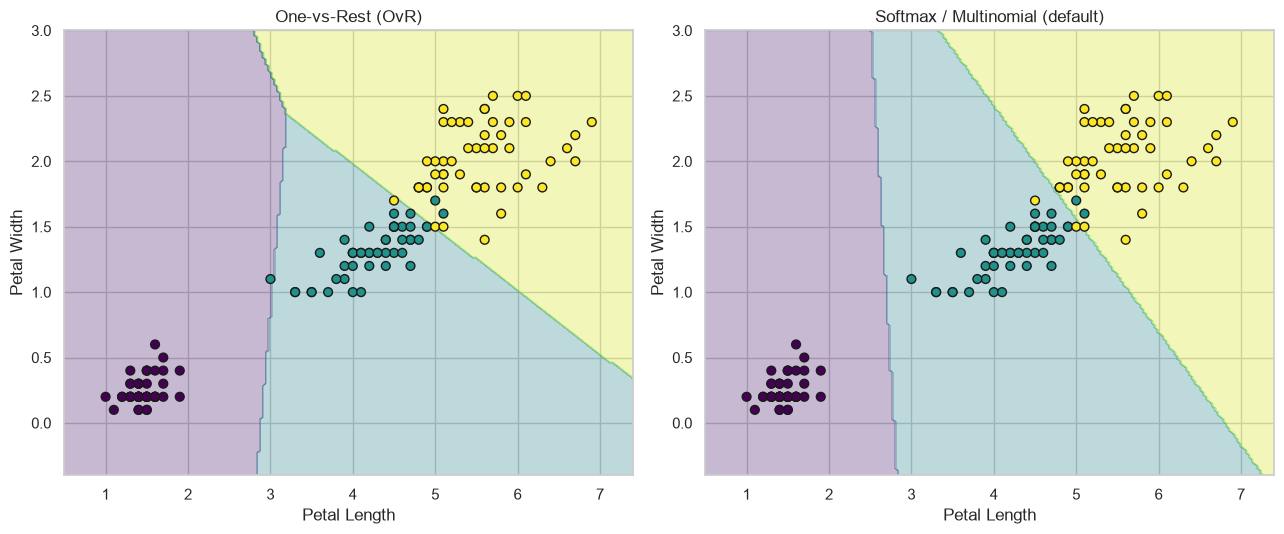

In [26]:
from sklearn.datasets import load_iris
from sklearn.multiclass import OneVsRestClassifier

iris_dataset = load_iris()
petal_features = iris_dataset.data[:, 2:4]   # just petal length & width, so we can plot in 2D
species_labels = iris_dataset.target

ovr_model = OneVsRestClassifier(LogisticRegression(max_iter=1000)).fit(petal_features, species_labels)
softmax_model = LogisticRegression(max_iter=1000).fit(petal_features, species_labels)   # multinomial/softmax by default

petal_x_grid, petal_y_grid = np.meshgrid(np.linspace(petal_features[:,0].min()-0.5, petal_features[:,0].max()+0.5, 200),
                        np.linspace(petal_features[:,1].min()-0.5, petal_features[:,1].max()+0.5, 200))
ovr_regions = ovr_model.predict(np.c_[petal_x_grid.ravel(), petal_y_grid.ravel()]).reshape(petal_x_grid.shape)
softmax_regions = softmax_model.predict(np.c_[petal_x_grid.ravel(), petal_y_grid.ravel()]).reshape(petal_x_grid.shape)

plot_figure, plot_axes = plt.subplots(1, 2, figsize=(13,5.5))
for plot_axis, grid_predictions, panel_title in zip(plot_axes, [ovr_regions, softmax_regions], ['One-vs-Rest (OvR)', 'Softmax / Multinomial (default)']):
    plot_axis.contourf(petal_x_grid, petal_y_grid, grid_predictions, alpha=0.3, cmap='viridis')
    plot_axis.scatter(petal_features[:,0], petal_features[:,1], c=species_labels, cmap='viridis', edgecolor='k', s=40)
    plot_axis.set_title(panel_title)
    plot_axis.set_xlabel('Petal Length'); plot_axis.set_ylabel('Petal Width')
plt.tight_layout()
plt.show()


In [27]:
# Softmax output always sums to exactly 1 across all classes
example_flower = petal_features[0].reshape(1, -1)
species_probabilities = softmax_model.predict_proba(example_flower)
print("Predicted probability for each class:", dict(zip(iris_dataset.target_names, species_probabilities[0].round(4))))
print("Total probability across classes:", species_probabilities.sum())


Predicted probability for each class: {np.str_('setosa'): np.float64(0.9798), np.str_('versicolor'): np.float64(0.0202), np.str_('virginica'): np.float64(0.0)}
Total probability across classes: 1.0


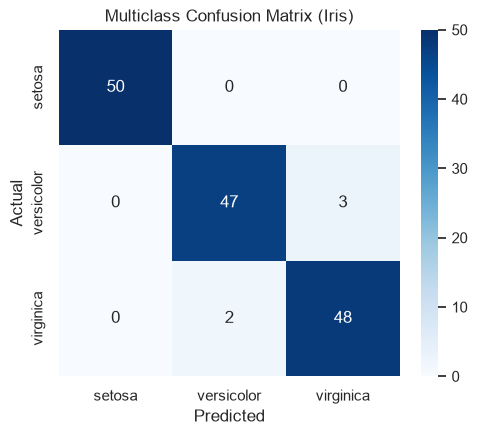

In [28]:
from sklearn.metrics import confusion_matrix

species_predictions = softmax_model.predict(petal_features)
species_confusion = confusion_matrix(species_labels, species_predictions)

plt.figure(figsize=(5.5,4.5))
sns.heatmap(species_confusion, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris_dataset.target_names, yticklabels=iris_dataset.target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Multiclass Confusion Matrix (Iris)')
plt.show()


In [29]:
print(classification_report(species_labels, species_predictions, target_names=iris_dataset.target_names))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        50
  versicolor       0.96      0.94      0.95        50
   virginica       0.94      0.96      0.95        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150

